In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

df = pd.read_csv("../data/processed/lfs_cleaned.csv")

X = df.drop(columns=["labor_status"])
y = df["labor_status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 53042
Testing samples: 13261


In [3]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

num_cols = ["age", "household_size"]
cat_cols = ["gender", "marital_status", "urban_rural", "district", "education_level"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols)
    ]
)

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

print("X_train shape:", X_train_prep.shape)
print("X_test shape:", X_test_prep.shape)

X_train shape: (53042, 43)
X_test shape: (13261, 43)


In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, f1_score

model_lr = LogisticRegression(max_iter=1000, random_state=42)
model_lr.fit(X_train_prep, y_train)

y_pred_lr = model_lr.predict(X_test_prep)

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Macro F1:", f1_score(y_test, y_pred_lr, average="macro"))
print("\nClassification Report:\n", classification_report(y_test, y_pred_lr))

Accuracy: 0.5976924817132946
Macro F1: 0.4123673545838431

Classification Report:
                      precision    recall  f1-score   support

           Employed       0.61      0.72      0.66      6719
         Unemployed       0.00      0.00      0.00      1170
out of labour force       0.58      0.57      0.57      5372

           accuracy                           0.60     13261
          macro avg       0.40      0.43      0.41     13261
       weighted avg       0.54      0.60      0.57     13261



c:\Users\user1\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\user1\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\user1\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

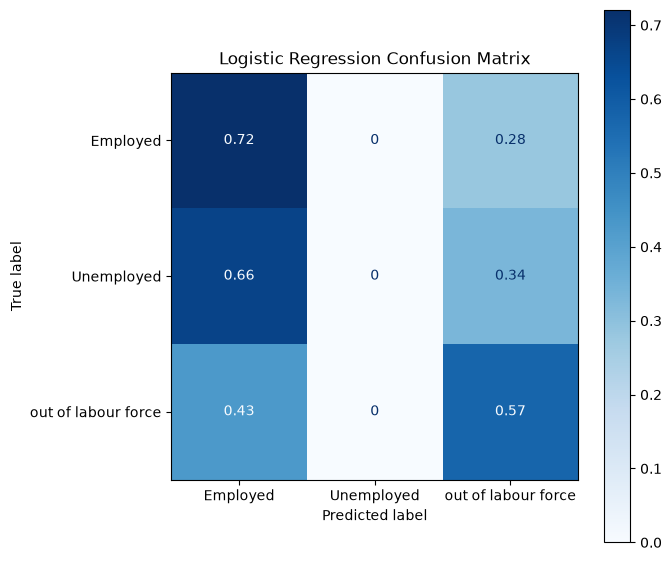

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred_lr, 
    cmap="Blues", 
    ax=ax,
    normalize="true"
)
plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.savefig("../figures/confusion_matrices/cm_logistic_regression.png", dpi=300)
plt.show()

Accuracy: 0.5152703416031973
Macro F1: 0.4472129367195717

Classification Report:
                      precision    recall  f1-score   support

           Employed       0.68      0.46      0.55      6719
         Unemployed       0.14      0.34      0.20      1170
out of labour force       0.57      0.62      0.59      5372

           accuracy                           0.52     13261
          macro avg       0.46      0.47      0.45     13261
       weighted avg       0.59      0.52      0.54     13261



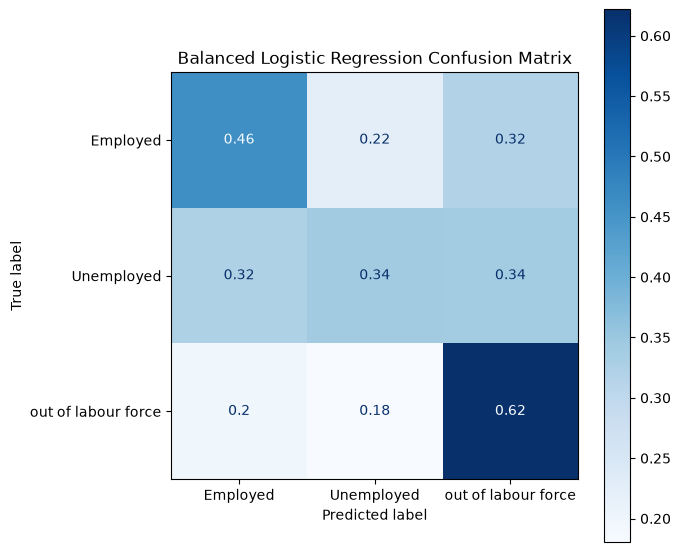

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, f1_score
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

model_lr_balanced = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
model_lr_balanced.fit(X_train_prep, y_train)

y_pred_lr_bal = model_lr_balanced.predict(X_test_prep)

print("Accuracy:", accuracy_score(y_test, y_pred_lr_bal))
print("Macro F1:", f1_score(y_test, y_pred_lr_bal, average="macro"))
print("\nClassification Report:\n", classification_report(y_test, y_pred_lr_bal))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred_lr_bal, 
    cmap="Blues", 
    ax=ax,
    normalize="true"
)
plt.title("Balanced Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.savefig("../figures/confusion_matrices/cm_logistic_regression_balanced.png", dpi=300)
plt.show()

In [7]:
from sklearn.ensemble import RandomForestClassifier

model_rf = RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=42, n_jobs=-1)
model_rf.fit(X_train_prep, y_train)

y_pred_rf = model_rf.predict(X_test_prep)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Macro F1:", f1_score(y_test, y_pred_rf, average="macro"))
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))

Accuracy: 0.6255938466179021
Macro F1: 0.514073827949299

Classification Report:
                      precision    recall  f1-score   support

           Employed       0.71      0.66      0.69      6719
         Unemployed       0.16      0.23      0.19      1170
out of labour force       0.67      0.67      0.67      5372

           accuracy                           0.63     13261
          macro avg       0.51      0.52      0.51     13261
       weighted avg       0.65      0.63      0.64     13261



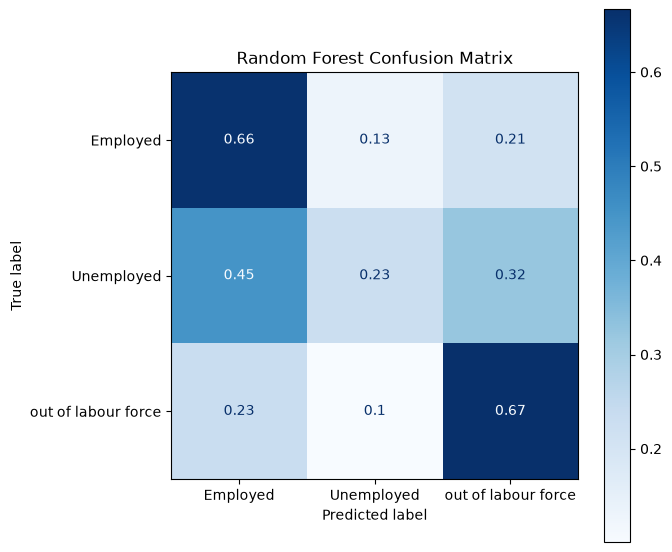

In [8]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred_rf, 
    cmap="Blues", 
    ax=ax,
    normalize="true"
)
plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.savefig("../figures/confusion_matrices/cm_random_forest.png", dpi=300)
plt.show()

In [9]:
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, accuracy_score, f1_score

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

sample_weights = compute_sample_weight("balanced", y_train_enc)

model_xgb = XGBClassifier(n_estimators=100, random_state=42, eval_metric="mlogloss")
model_xgb.fit(X_train_prep, y_train_enc, sample_weight=sample_weights)

y_pred_xgb_enc = model_xgb.predict(X_test_prep)
y_pred_xgb = le.inverse_transform(y_pred_xgb_enc)

print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("Macro F1:", f1_score(y_test, y_pred_xgb, average="macro"))
print("\nClassification Report:\n", classification_report(y_test, y_pred_xgb))

Accuracy: 0.5676796621672574
Macro F1: 0.5034348595762186

Classification Report:
                      precision    recall  f1-score   support

           Employed       0.73      0.56      0.63      6719
         Unemployed       0.15      0.45      0.22      1170
out of labour force       0.71      0.61      0.66      5372

           accuracy                           0.57     13261
          macro avg       0.53      0.54      0.50     13261
       weighted avg       0.67      0.57      0.61     13261



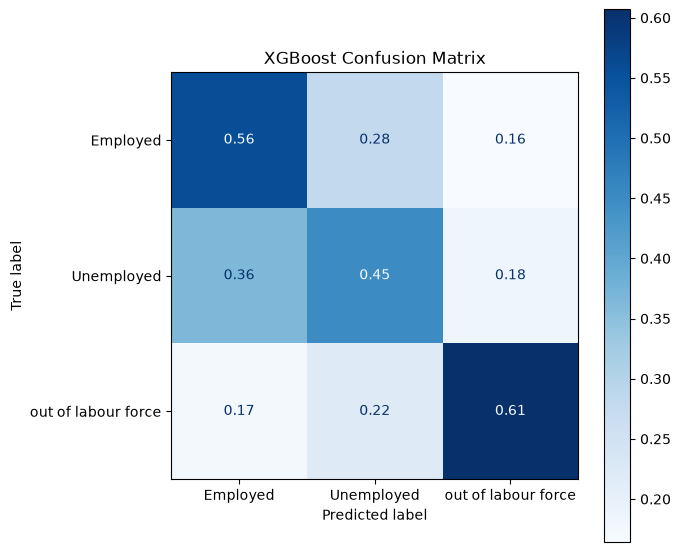

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred_xgb, 
    cmap="Blues", 
    ax=ax,
    normalize="true"
)
plt.title("XGBoost Confusion Matrix")
plt.tight_layout()
plt.savefig("../figures/confusion_matrices/cm_xgboost.png", dpi=300)
plt.show()

In [11]:
from sklearn.metrics import recall_score

results = [
    {
        "Model": "Baseline Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred_lr),
        "Macro F1": f1_score(y_test, y_pred_lr, average="macro"),
        "Unemployed Recall": recall_score(y_test, y_pred_lr, average=None, labels=model_lr.classes_)[list(model_lr.classes_).index("Unemployed")]
    },
    {
        "Model": "Balanced Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred_lr_bal),
        "Macro F1": f1_score(y_test, y_pred_lr_bal, average="macro"),
        "Unemployed Recall": recall_score(y_test, y_pred_lr_bal, average=None, labels=model_lr_balanced.classes_)[list(model_lr_balanced.classes_).index("Unemployed")]
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, y_pred_rf),
        "Macro F1": f1_score(y_test, y_pred_rf, average="macro"),
        "Unemployed Recall": recall_score(y_test, y_pred_rf, average=None, labels=model_rf.classes_)[list(model_rf.classes_).index("Unemployed")]
    },
    {
        "Model": "XGBoost",
        "Accuracy": accuracy_score(y_test, y_pred_xgb),
        "Macro F1": f1_score(y_test, y_pred_xgb, average="macro"),
        "Unemployed Recall": recall_score(y_test, y_pred_xgb, average=None, labels=le.classes_)[list(le.classes_).index("Unemployed")]
    }
]

df_results = pd.DataFrame(results)
print(df_results.to_string(index=False))

                       Model  Accuracy  Macro F1  Unemployed Recall
Baseline Logistic Regression  0.597692  0.412367           0.000000
Balanced Logistic Regression  0.515270  0.447213           0.339316
               Random Forest  0.625594  0.514074           0.228205
                     XGBoost  0.567680  0.503435           0.451282


In [12]:
import joblib

joblib.dump(model_rf, "../models/classical/random_forest_model.joblib")
joblib.dump(preprocessor, "../models/classical/preprocessor.joblib")
print("Models saved successfully!")

Models saved successfully!


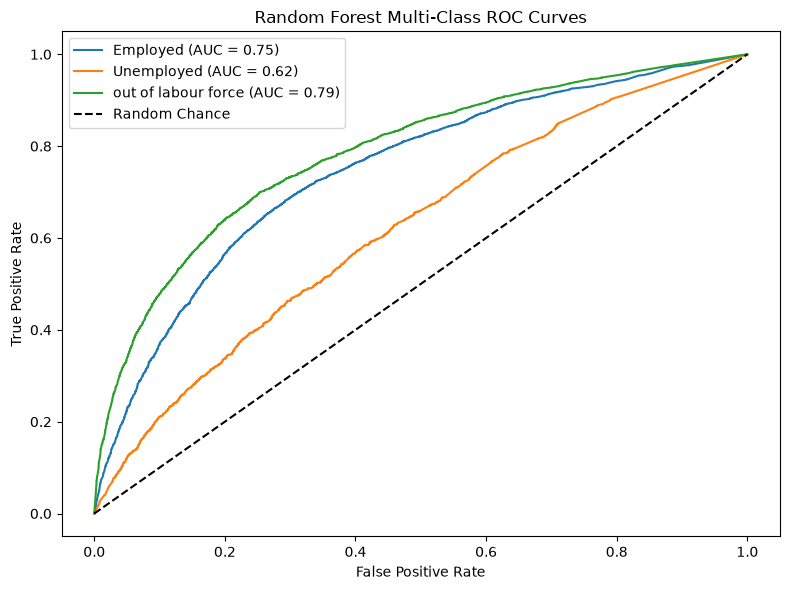

In [13]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

y_test_bin = label_binarize(y_test, classes=model_rf.classes_)
y_score_rf = model_rf.predict_proba(X_test_prep)

plt.figure(figsize=(8, 6))

for i, class_name in enumerate(model_rf.classes_):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score_rf[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{class_name} (AUC = {roc_auc:.2f})")

plt.plot([0, 1], [0, 1], "k--", label="Random Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest Multi-Class ROC Curves")
plt.legend()
plt.tight_layout()
plt.savefig("../figures/roc_pr_curves/rf_roc_curve.png", dpi=300)
plt.show()

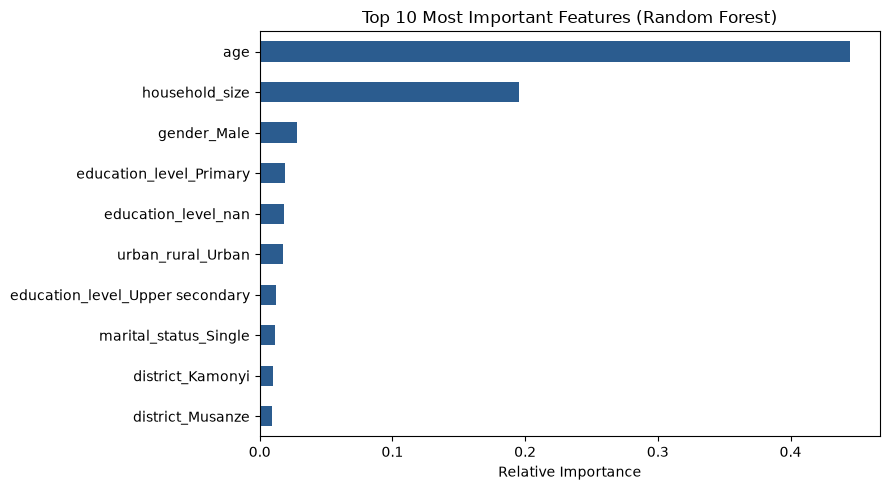

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cat_encoder = preprocessor.named_transformers_["cat"]
encoded_cat_cols = cat_encoder.get_feature_names_out(cat_cols)
all_features = num_cols + list(encoded_cat_cols)

importances = model_rf.feature_importances_
feat_imp = pd.Series(importances, index=all_features).sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 5))
feat_imp.sort_values().plot(kind="barh", color="#2b5c8f")
plt.title("Top 10 Most Important Features (Random Forest)")
plt.xlabel("Relative Importance")
plt.tight_layout()
plt.savefig("../figures/rf_feature_importance.png", dpi=300)
plt.show()

In [16]:
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import scipy.sparse as sp

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_prep, y_train_enc, test_size=0.15, random_state=42, stratify=y_train_enc
)

if sp.issparse(X_tr):
    X_tr_dense = X_tr.toarray().astype(np.float32)
    X_val_dense = X_val.toarray().astype(np.float32)
    X_test_dense = X_test_prep.toarray().astype(np.float32)
else:
    X_tr_dense = np.asarray(X_tr, dtype=np.float32)
    X_val_dense = np.asarray(X_val, dtype=np.float32)
    X_test_dense = np.asarray(X_test_prep, dtype=np.float32)

BATCH_SIZE = 128

train_ds = (
    tf.data.Dataset.from_tensor_slices((X_tr_dense, y_tr))
    .shuffle(buffer_size=len(X_tr_dense), seed=42)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    tf.data.Dataset.from_tensor_slices((X_val_dense, y_val))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
    tf.data.Dataset.from_tensor_slices((X_test_dense, y_test_enc))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

classes = np.unique(y_train_enc)
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train_enc)
dl_class_weights = dict(zip(classes, weights))

model_nn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_tr_dense.shape[1],)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(3, activation="softmax")
])

model_nn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_nn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         5,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,835 (65.76 KB)

 Trainable params: 16,451 (64.26 KB)

 Non-trainable params: 384 (1.50 KB)

Epoch 1/40


c:\Users\user1\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


353/353 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.4787 - loss: 1.0798 - val_accuracy: 0.5603 - val_loss: 0.9613
Epoch 2/40
353/353 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5258 - loss: 0.9985 - val_accuracy: 0.5438 - val_loss: 0.9401
Epoch 3/40
353/353 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.5350 - loss: 0.9768 - val_accuracy: 0.5560 - val_loss: 0.9389
Epoch 4/40
353/353 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.5475 - loss: 0.9641 - val_accuracy: 0.5458 - val_loss: 0.9460
Epoch 5/40
353/353 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.5469 - loss: 0.9552 - val_accuracy: 0.5561 - val_loss: 0.9355
Epoch 6/40
353/353 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.5470 - loss: 0.9541 - val_accuracy: 0.5609 - val_loss: 0.9208
Epoch 7/40
353/353 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.5520 - loss: 0.9453 - val_accuracy: 0.5572 - val_loss: 0.9247
Epoch 8/40
353/353 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.5547 - loss: 0.9438 - val_accuracy: 0.5447 - v

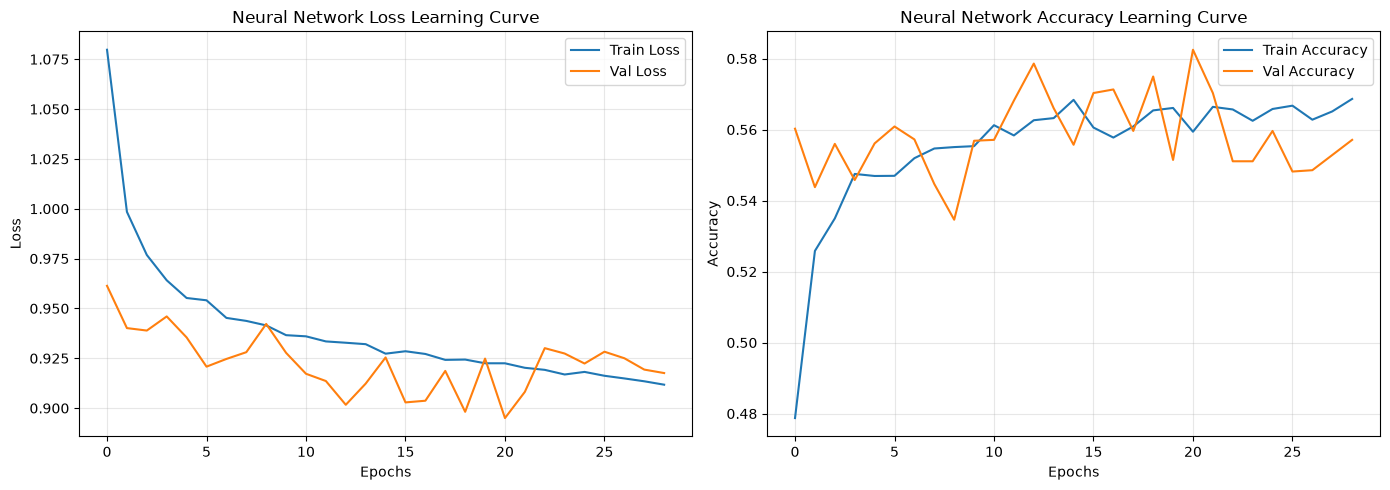

In [17]:
import matplotlib.pyplot as plt

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", 
    patience=8, 
    restore_best_weights=True
)

history = model_nn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    class_weight=dl_class_weights,
    callbacks=[early_stop],
    verbose=1
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history.history["loss"], label="Train Loss", color="#1f77b4")
ax1.plot(history.history["val_loss"], label="Val Loss", color="#ff7f0e")
ax1.set_title("Neural Network Loss Learning Curve")
ax1.set_xlabel("Epochs")
ax1.set_ylabel("Loss")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(history.history["accuracy"], label="Train Accuracy", color="#1f77b4")
ax2.plot(history.history["val_accuracy"], label="Val Accuracy", color="#ff7f0e")
ax2.set_title("Neural Network Accuracy Learning Curve")
ax2.set_xlabel("Epochs")
ax2.set_ylabel("Accuracy")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../figures/dl_learning_curves.png", dpi=300)
plt.show()

104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
Accuracy: 0.5875876630721665
Macro F1: 0.5109213222633914

Classification Report:
                      precision    recall  f1-score   support

           Employed       0.73      0.59      0.65      6719
         Unemployed       0.15      0.39      0.22      1170
out of labour force       0.70      0.63      0.66      5372

           accuracy                           0.59     13261
          macro avg       0.53      0.54      0.51     13261
       weighted avg       0.67      0.59      0.62     13261



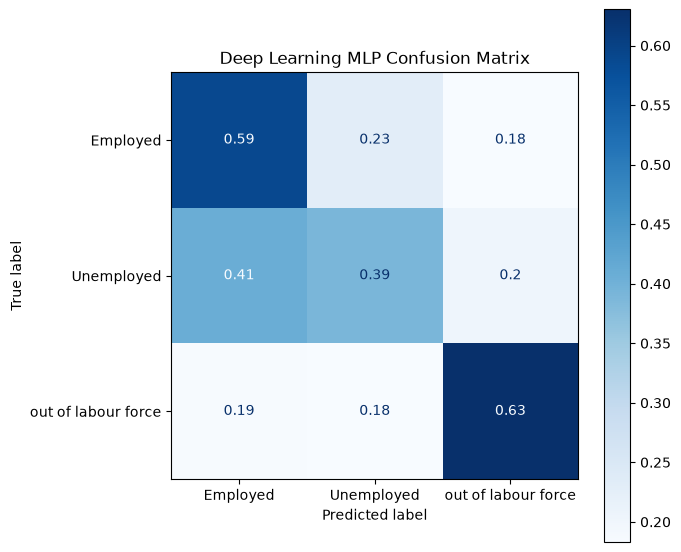

In [18]:
from sklearn.metrics import classification_report, accuracy_score, f1_score, ConfusionMatrixDisplay

y_pred_probs = model_nn.predict(test_ds)
y_pred_nn_enc = np.argmax(y_pred_probs, axis=1)
y_pred_nn = le.inverse_transform(y_pred_nn_enc)

print("Accuracy:", accuracy_score(y_test, y_pred_nn))
print("Macro F1:", f1_score(y_test, y_pred_nn, average="macro"))
print("\nClassification Report:\n", classification_report(y_test, y_pred_nn))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred_nn, 
    cmap="Blues", 
    ax=ax,
    normalize="true"
)
plt.title("Deep Learning MLP Confusion Matrix")
plt.tight_layout()
plt.savefig("../figures/confusion_matrices/cm_deep_learning_mlp.png", dpi=300)
plt.show()

model_nn.save("../models/deep_learning_mlp.keras")

In [19]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, recall_score

all_results = [
    {
        "Model": "Baseline Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred_lr),
        "Macro F1": f1_score(y_test, y_pred_lr, average="macro"),
        "Unemployed Recall": recall_score(y_test, y_pred_lr, average=None, labels=model_lr.classes_)[list(model_lr.classes_).index("Unemployed")]
    },
    {
        "Model": "Balanced Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred_lr_bal),
        "Macro F1": f1_score(y_test, y_pred_lr_bal, average="macro"),
        "Unemployed Recall": recall_score(y_test, y_pred_lr_bal, average=None, labels=model_lr_balanced.classes_)[list(model_lr_balanced.classes_).index("Unemployed")]
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, y_pred_rf),
        "Macro F1": f1_score(y_test, y_pred_rf, average="macro"),
        "Unemployed Recall": recall_score(y_test, y_pred_rf, average=None, labels=model_rf.classes_)[list(model_rf.classes_).index("Unemployed")]
    },
    {
        "Model": "XGBoost",
        "Accuracy": accuracy_score(y_test, y_pred_xgb),
        "Macro F1": f1_score(y_test, y_pred_xgb, average="macro"),
        "Unemployed Recall": recall_score(y_test, y_pred_xgb, average=None, labels=le.classes_)[list(le.classes_).index("Unemployed")]
    },
    {
        "Model": "Deep Learning MLP",
        "Accuracy": accuracy_score(y_test, y_pred_nn),
        "Macro F1": f1_score(y_test, y_pred_nn, average="macro"),
        "Unemployed Recall": recall_score(y_test, y_pred_nn, average=None, labels=le.classes_)[list(le.classes_).index("Unemployed")]
    }
]

df_all_results = pd.DataFrame(all_results)
print(df_all_results.to_string(index=False))

                       Model  Accuracy  Macro F1  Unemployed Recall
Baseline Logistic Regression  0.597692  0.412367           0.000000
Balanced Logistic Regression  0.515270  0.447213           0.339316
               Random Forest  0.625594  0.514074           0.228205
                     XGBoost  0.567680  0.503435           0.451282
           Deep Learning MLP  0.587588  0.510921           0.390598
